In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [8]:
df = pd.read_csv(
    r"C:\Users\matt9\Downloads\archive (3)\amz_uk_price_prediction_dataset.csv"
)

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [9]:
# Checking for missing data
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [10]:
# Identifying columns in the dataframe where over 80% of the values are missing
df.columns[df.isnull().mean() > 0.8]


Index([], dtype='object')

In [11]:
# Frequency table for 'category'
frequency_table = df['category'].value_counts()
frequency_table.sort_values(ascending=False).head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

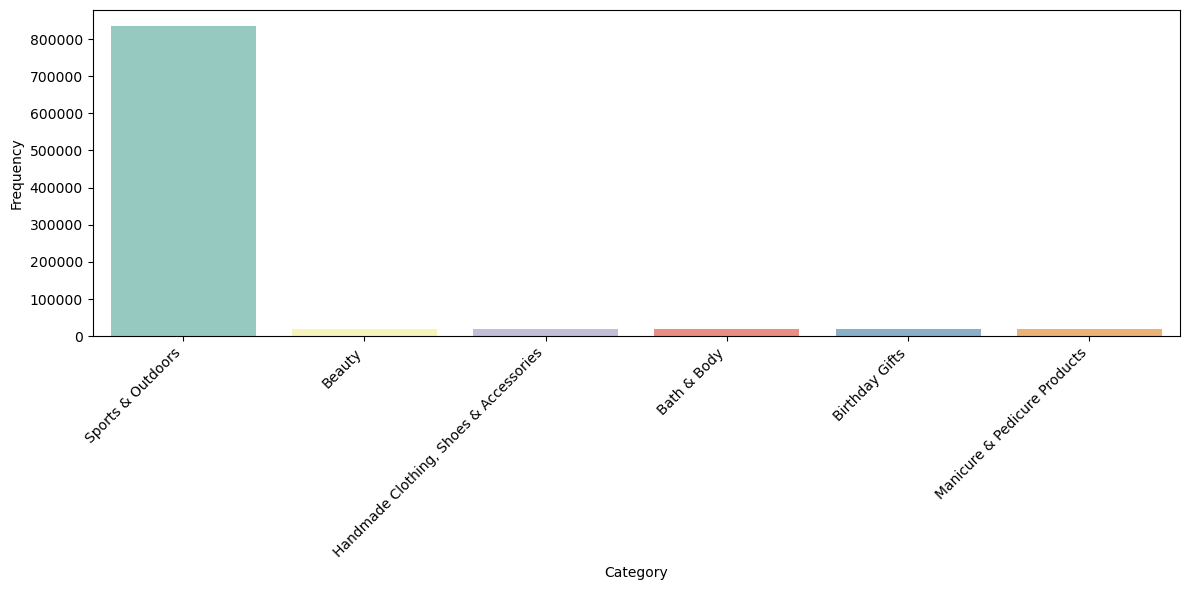

In [23]:
frequency_table_sample = frequency_table.sort_values(ascending=False).head(6)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=frequency_table_sample.index,
    y=frequency_table_sample.values,
    hue=frequency_table_sample.index,
    palette="Set3",
    legend=False
)

ax.set_xlabel("Category")
ax.set_ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

<Axes: ylabel='count'>

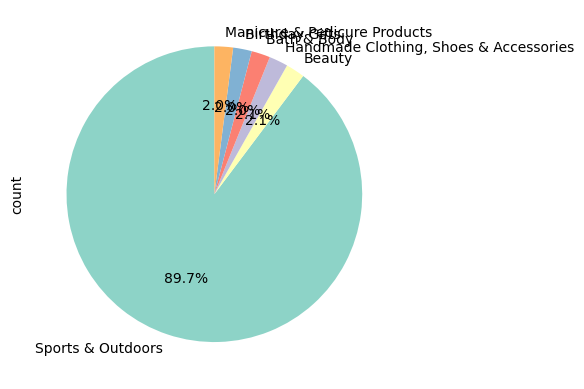

In [29]:
top_categories = df["category"].value_counts().head(6).index
df2 = df[df["category"].isin(top_categories)]


df2['category'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

In [14]:
mean_price =df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()
mean_price, median_price, mode_price

(np.float64(89.24380943923661),
 19.09,
 0    9.99
 Name: price, dtype: float64)

In [15]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])
variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price

(119445.48532256528,
 345.60886175352226,
 0.0,
 100000.0,
 100000.0,
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

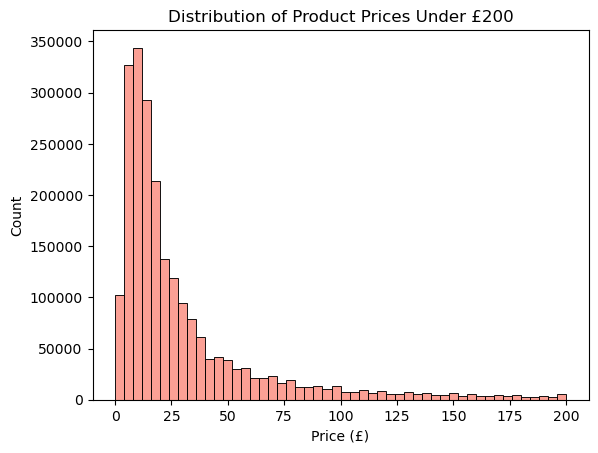

In [16]:
price_under_200 = df[df["price"] <= 200]

sns.histplot(data=price_under_200, x="price", bins=50, color="salmon")
plt.title("Distribution of Product Prices Under £200")
plt.xlabel("Price (£)")
plt.show()

<Axes: ylabel='price'>

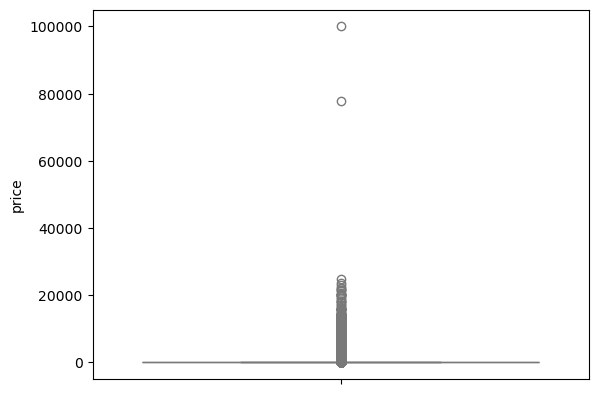

In [17]:
sns.boxplot(data = df['price'], color="lightblue")

In [30]:
df2 = df[df['stars'] > 0]

mean_stars = df2['stars'].mean()
median_stars = df2['stars'].median()
mode_stars = df2['stars'].mode()
mean_stars, median_stars, mode_stars

(np.float64(4.319160762226911),
 4.4,
 0    4.5
 Name: stars, dtype: float64)

In [32]:
variance_stars = df2['stars'].var()
std_dev_stars = df2['stars'].std()
min_stars = df2['stars'].min()
max_stars = df2['stars'].max()
range_stars = max_stars - min_stars
quantiles_stars = df2['stars'].quantile([0.25, 0.5, 0.75])
variance_stars, std_dev_stars, min_stars, max_stars, range_stars, quantiles_stars

(0.3083433752380519,
 0.5552867504614637,
 1.0,
 5.0,
 4.0,
 0.25    4.1
 0.50    4.4
 0.75    4.6
 Name: stars, dtype: float64)

In [33]:
skewness_stars = df2['stars'].skew()
kurtosis_stars = df2['stars'].kurtosis()

skewness_stars, kurtosis_stars

(np.float64(-2.379568112212799), np.float64(9.78193769066435))

<Axes: xlabel='stars', ylabel='Count'>

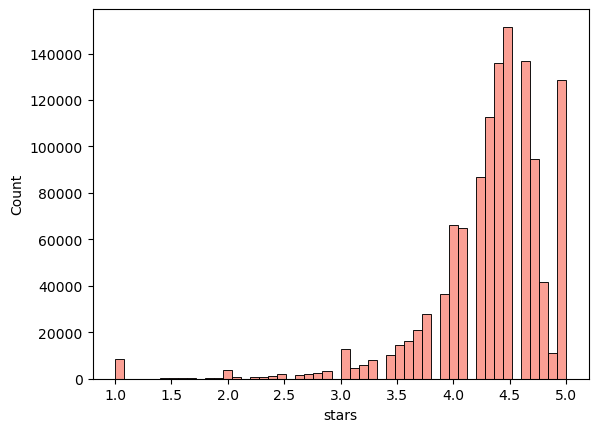

In [34]:
sns.histplot(data=df2, x="stars", bins=50, color="salmon")